# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** [Isi nama Anda]
- **Email:** fachrezaarfianta@gmail.com
- **ID Dicoding:** [Isi ID Dicoding Anda]

## Menentukan Pertanyaan Bisnis

Bayangkan kita adalah tim analitik sebuah layanan bike sharing (Capital Bikeshare, Washington D.C.) yang ingin mengoptimalkan operasional armada dan promosi berdasarkan data peminjaman sepeda selama **2011-2012**. Pertanyaan berikut disusun dengan metode SMART.

**Pertanyaan 1 (Pola jam)**
> Pada jam berapa (00-23) rata-rata jumlah penyewaan sepeda per jam (`cnt`) mencapai puncak pada **hari kerja** dibandingkan **hari non-kerja** sepanjang 2011-2012, dan berapa persen penyewa pada jam puncak tersebut yang merupakan pengguna terdaftar (*registered*)?

| Elemen | Penjelasan |
|---|---|
| Specific | Fokus pada jam puncak, dibedakan hari kerja vs non-kerja, dan jenis pengguna |
| Measurable | Rata-rata `cnt` per jam dan persentase `registered` |
| Action-oriented | Menentukan jam redistribusi sepeda dan penempatan petugas/armada |
| Relevant | Ketersediaan sepeda pada jam sibuk adalah inti kualitas layanan |
| Time-bound | Periode 2011-2012 |

**Pertanyaan 2 (Cuaca dan musim)**
> Berapa persen penurunan rata-rata penyewaan **harian** saat cuaca berawan/berkabut dan saat hujan/salju ringan dibandingkan cuaca cerah, dan pada musim apa rata-rata penyewaan harian tertinggi selama 2011-2012?

| Elemen | Penjelasan |
|---|---|
| Specific | Membandingkan kategori cuaca (`weathersit`) dan musim (`season`) terhadap penyewaan harian |
| Measurable | Persentase penurunan terhadap cuaca cerah dan rata-rata harian per musim |
| Action-oriented | Dasar menentukan waktu promosi dan jadwal perawatan armada |
| Relevant | Cuaca dan musim adalah faktor eksternal utama permintaan |
| Time-bound | Periode 2011-2012 |

**Pertanyaan 3 (Pertumbuhan)**
> Berapa persen pertumbuhan rata-rata penyewaan harian pada tahun 2012 dibandingkan 2011 (Year-over-Year), baik secara keseluruhan maupun per bulan, dan pada bulan apa pertumbuhan paling tinggi dan paling rendah?

| Elemen | Penjelasan |
|---|---|
| Specific | Membandingkan tiap bulan 2012 terhadap bulan yang sama di 2011 |
| Measurable | Persentase pertumbuhan YoY |
| Action-oriented | Perencanaan kapasitas armada dan waktu penambahan sepeda |
| Relevant | Pertumbuhan menunjukkan kesehatan bisnis dan kebutuhan ekspansi |
| Time-bound | 2011 vs 2012 |

## Menyiapkan semua library yang dibutuhkan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Palet yang konsisten dan ramah buta warna
C_WORK = "#1F77B4"   # hari kerja / 2012
C_OFF = "#E8833A"    # hari non-kerja / 2011
C_MUTED = "#B8BEC6"  # batang non-sorotan
C_HIGHLIGHT = "#1F77B4"

## Data Wrangling

### Gathering Data

Dataset terdiri dari dua file:
- `day.csv`: agregasi peminjaman **harian** (731 baris)
- `hour.csv`: peminjaman **per jam** (17.379 baris, ada kolom tambahan `hr`)

Keterangan kolom penting: `season` (1 Spring, 2 Summer, 3 Fall, 4 Winter), `yr` (0 = 2011, 1 = 2012), `weathersit` (1 cerah, 2 berawan/berkabut, 3 hujan/salju ringan, 4 hujan lebat/badai), `temp`, `atemp`, `hum`, `windspeed` (sudah dinormalisasi), `casual` (pengguna tidak terdaftar), `registered` (pengguna terdaftar), `cnt` (total = casual + registered).

In [2]:
# Letakkan day.csv dan hour.csv di folder "data/" (atau di folder yang sama dengan notebook ini)
DATA_DIR = "data" if os.path.exists("data/day.csv") else "."

day_df = pd.read_csv(f"{DATA_DIR}/day.csv")
hour_df = pd.read_csv(f"{DATA_DIR}/hour.csv")

print("day_df  :", day_df.shape)
print("hour_df :", hour_df.shape)
day_df.head()

day_df  : (731, 16)
hour_df : (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Kedua file berhasil dimuat. `hour.csv` memiliki kolom yang sama dengan `day.csv` ditambah kolom `hr`.
- Kolom `dteday` perlu diperiksa tipe datanya, dan banyak kolom kategori masih berupa kode angka.

### Assessing Data

In [4]:
print("=== day_df ===")
day_df.info()
print()
print("=== hour_df ===")
hour_df.info()

=== day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB

=== hour_df ===
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data column

In [5]:
# 1. Missing value dan data duplikat
print("Missing value day_df :", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())
print("Duplikat day_df      :", day_df.duplicated().sum())
print("Duplikat hour_df     :", hour_df.duplicated().sum())

Missing value day_df : 0
Missing value hour_df: 0
Duplikat day_df      : 0
Duplikat hour_df     : 0


In [6]:
# 2. Statistik deskriptif untuk mencari nilai yang janggal
day_df.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


In [7]:
hour_df.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


In [8]:
# 3. Invalid value: kelembapan (hum) bernilai 0 padahal tidak realistis
print("day_df  - baris dengan hum == 0:")
display(day_df[day_df["hum"] == 0][["dteday", "season", "weathersit", "temp", "hum", "cnt"]])

hum0_hours = hour_df[hour_df["hum"] == 0]
print("hour_df - jumlah baris dengan hum == 0:", len(hum0_hours))
print("hour_df - tanggal terdampak:", hum0_hours["dteday"].unique())

day_df  - baris dengan hum == 0:


,dteday,season,weathersit,temp,hum,cnt
68,2011-03-10,1,3,0.389091,0.0,623


hour_df - jumlah baris dengan hum == 0: 22
hour_df - tanggal terdampak: <StringArray>
['2011-03-10']
Length: 1, dtype: str


In [9]:
# 4. Windspeed bernilai 0 (kemungkinan nilai yang tidak tercatat)
print("Proporsi windspeed == 0 di hour_df:", round((hour_df["windspeed"] == 0).mean() * 100, 1), "%")
print("Proporsi windspeed == 0 di day_df :", round((day_df["windspeed"] == 0).mean() * 100, 1), "%")

Proporsi windspeed == 0 di hour_df: 12.5 %
Proporsi windspeed == 0 di day_df : 0.0 %


In [10]:
# 5. Data jam yang hilang: seharusnya 24 jam x jumlah hari
expected_rows = hour_df["dteday"].nunique() * 24
print("Jumlah hari di hour_df       :", hour_df["dteday"].nunique())
print("Baris yang seharusnya ada    :", expected_rows)
print("Baris yang ada               :", len(hour_df))
print("Jam yang tidak tercatat      :", expected_rows - len(hour_df))

Jumlah hari di hour_df       : 731
Baris yang seharusnya ada    : 17544
Baris yang ada               : 17379
Jam yang tidak tercatat      : 165


In [11]:
# 6. Konsistensi nilai: cnt harus sama dengan casual + registered
print("Baris day_df  tidak konsisten:", (day_df["cnt"] != day_df["casual"] + day_df["registered"]).sum())
print("Baris hour_df tidak konsisten:", (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum())

# 7. Outlier pada cnt (metode IQR)
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print("Outlier cnt day_df  :", count_outliers(day_df["cnt"]))
print("Outlier cnt hour_df :", count_outliers(hour_df["cnt"]), "dari", len(hour_df), "baris")
print("Kategori weathersit 4 di hour_df:", (hour_df["weathersit"] == 4).sum(), "baris;",
      "di day_df:", (day_df["weathersit"] == 4).sum(), "baris")

Baris day_df  tidak konsisten: 0
Baris hour_df tidak konsisten: 0
Outlier cnt day_df  : 0
Outlier cnt hour_df : 505 dari 17379 baris
Kategori weathersit 4 di hour_df: 3 baris; di day_df: 0 baris


**Insight (masalah yang ditemukan):**
1. **Tipe data tidak sesuai**: `dteday` bertipe teks, bukan tanggal. *Solusi:* ubah ke `datetime`.
2. **Invalid value**: `hum` bernilai 0 (satu hari pada `day_df`, 2011-03-10, dan jam-jam pada tanggal yang sama di `hour_df`). Kelembapan 0% tidak realistis. *Solusi:* tandai sebagai NaN lalu isi dengan median `hum` pada bulan dan tahun yang sama.
3. **Nilai kategori berupa kode angka** (`season`, `yr`, `mnth`, `weekday`, `weathersit`, `workingday`) dan **nilai suhu/kelembapan/angin ternormalisasi**. *Solusi:* beri label yang mudah dibaca dan kembalikan ke skala aslinya (suhu x 41 = °C, hum x 100 = %, windspeed x 67 = km/jam).
4. **Data jam tidak lengkap**: terdapat sekitar 165 jam yang tidak tercatat di `hour_df`. *Solusi:* tidak diisi, karena analisis memakai rata-rata per jam sehingga tidak bias; hal ini dicatat sebagai keterbatasan.
5. **Windspeed = 0** pada sekitar 12,5% baris `hour_df`, kemungkinan nilai tidak tercatat. *Solusi:* kolom ini tidak dipakai dalam analisis sehingga dibiarkan.
6. **Outlier** pada `cnt` per jam adalah fluktuasi permintaan yang wajar (jam sibuk), bukan kesalahan data. *Solusi:* dipertahankan.
7. Tidak ada missing value maupun data duplikat, dan `cnt = casual + registered` konsisten di seluruh baris.

### Cleaning Data

In [12]:
# 1. Ubah dteday ke datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
print(day_df["dteday"].dtype, hour_df["dteday"].dtype)

datetime64[us] datetime64[us]


In [13]:
# 2. Tangani hum == 0 (invalid): jadikan NaN lalu isi dengan median bulan-tahun yang sama
for df in (day_df, hour_df):
    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = df.groupby(["yr", "mnth"])["hum"].transform(lambda s: s.fillna(s.median()))

print("hum == 0 / NaN di day_df :", (day_df["hum"] == 0).sum(), "/", day_df["hum"].isna().sum())
print("hum == 0 / NaN di hour_df:", (hour_df["hum"] == 0).sum(), "/", hour_df["hum"].isna().sum())
print("Nilai hum pada 2011-03-10 setelah dibersihkan:", round(day_df.loc[day_df["dteday"] == "2011-03-10", "hum"].iloc[0], 3))

hum == 0 / NaN di day_df : 0 / 0
hum == 0 / NaN di hour_df: 0 / 0
Nilai hum pada 2011-03-10 setelah dibersihkan: 0.573


In [14]:
# 3. Beri label kategori dan kembalikan skala asli
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
year_map = {0: 2011, 1: 2012}
month_map = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
             7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
weather_map = {1: "Cerah", 2: "Berawan/Kabut", 3: "Hujan/Salju Ringan", 4: "Hujan Lebat/Badai"}
workday_map = {0: "Non-kerja", 1: "Hari kerja"}

for df in (day_df, hour_df):
    df["season_label"] = df["season"].map(season_map)
    df["year"] = df["yr"].map(year_map)
    df["month_label"] = df["mnth"].map(month_map)
    df["weekday_label"] = df["weekday"].map(weekday_map)
    df["weather_label"] = df["weathersit"].map(weather_map)
    df["daytype"] = df["workingday"].map(workday_map)
    df["temp_c"] = df["temp"] * 41
    df["atemp_c"] = df["atemp"] * 50
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67

day_df[["dteday", "season_label", "year", "weather_label", "daytype", "temp_c", "hum_pct", "cnt"]].head()

,dteday,season_label,year,weather_label,daytype,temp_c,hum_pct,cnt
0,2011-01-01,Spring,2011,Berawan/Kabut,Non-kerja,14.110847,80.5833,985
1,2011-01-02,Spring,2011,Berawan/Kabut,Non-kerja,14.902598,69.6087,801
2,2011-01-03,Spring,2011,Cerah,Hari kerja,8.050924,43.7273,1349
3,2011-01-04,Spring,2011,Cerah,Hari kerja,8.200000,59.0435,1562
4,2011-01-05,Spring,2011,Cerah,Hari kerja,9.305237,43.6957,1600


In [15]:
# Pemeriksaan akhir
print("Missing value day_df :", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())
print("Rentang tanggal:", day_df["dteday"].min().date(), "s.d.", day_df["dteday"].max().date())
print("Rentang suhu (°C):", round(day_df["temp_c"].min(), 1), "-", round(day_df["temp_c"].max(), 1))

Missing value day_df : 0
Missing value hour_df: 0
Rentang tanggal: 2011-01-01 s.d. 2012-12-31
Rentang suhu (°C): 2.4 - 35.3


Data yang sudah bersih disimpan ke folder `dashboard/` agar dapat dipakai oleh dashboard Streamlit.

In [16]:
os.makedirs("dashboard", exist_ok=True)
day_df.to_csv("dashboard/day_clean.csv", index=False)
hour_df.to_csv("dashboard/hour_clean.csv", index=False)
print("Data bersih tersimpan di folder dashboard/")

Data bersih tersimpan di folder dashboard/


**Insight:**
- Tipe data tanggal sudah benar dan nilai kelembapan yang tidak valid sudah diperbaiki.
- Kolom kategori kini memiliki label yang mudah dibaca dan suhu/kelembapan/angin berada pada skala aslinya, sehingga siap dianalisis.

## Exploratory Data Analysis (EDA)

### Eksplorasi Data Umum

In [17]:
day_df[["cnt", "casual", "registered", "temp_c", "hum_pct", "windspeed_kmh"]].describe().round(1)

,cnt,casual,registered,temp_c,hum_pct,windspeed_kmh
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,4504.3,848.2,3656.2,20.3,62.9,12.8
std,1937.2,686.6,1560.3,7.5,14.1,5.2
min,22.0,2.0,20.0,2.4,18.8,1.5
25%,3152.0,315.5,2497.0,13.8,52.1,9.0
50%,4548.0,713.0,3662.0,20.4,62.7,12.1
75%,5956.0,1096.0,4776.5,26.9,73.0,15.6
max,8714.0,3410.0,6946.0,35.3,97.2,34.0


In [18]:
# Komposisi pengguna secara keseluruhan
total = day_df[["casual", "registered"]].sum()
print("Total penyewaan 2011-2012:", f"{day_df['cnt'].sum():,}")
print((total / total.sum() * 100).round(1).astype(str) + " %")

Total penyewaan 2011-2012: 3,292,679
casual        18.8 %
registered    81.2 %
dtype: str


In [19]:
# Korelasi variabel numerik dengan jumlah penyewaan harian
day_df[["cnt", "temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]].corr()["cnt"].round(2)

cnt              1.00
temp_c           0.63
atemp_c          0.63
hum_pct         -0.11
windspeed_kmh   -0.23
Name: cnt, dtype: float64

**Insight:**
- Pengguna **registered** mendominasi penyewaan dibanding **casual**.
- Suhu memiliki korelasi positif dengan jumlah penyewaan, sedangkan kelembapan dan kecepatan angin cenderung negatif atau lemah. Ini mengarahkan kita menelusuri efek cuaca dan musim pada pertanyaan 2.

### Eksplorasi Pertanyaan 1: Jam puncak hari kerja vs hari non-kerja

In [20]:
hourly = (hour_df.groupby(["daytype", "hr"])["cnt"].mean().unstack(0).round(1))
hourly.loc[[6, 7, 8, 9, 12, 13, 16, 17, 18, 19]]

daytype,Hari kerja,Non-kerja
hr,,
6,102.5,18.7
7,290.6,43.4
8,477.0,105.7
9,241.5,171.6
12,200.8,366.3
13,198.4,372.7
16,293.1,352.7
17,525.3,323.5
18,492.2,281.1


In [21]:
# Jam puncak per jenis hari
peak = hourly.idxmax().to_frame("jam_puncak")
peak["rata2_cnt_puncak"] = hourly.max()
peak

,jam_puncak,rata2_cnt_puncak
daytype,,
Hari kerja,17,525.3
Non-kerja,13,372.7


In [22]:
# Dua puncak pada hari kerja (pagi dan sore) serta proporsi pengguna registered pada jam tersebut
workday_hr = hour_df[hour_df["workingday"] == 1].groupby("hr")[["casual", "registered", "cnt"]].mean()
morning_peak = workday_hr.loc[6:10, "cnt"].idxmax()
evening_peak = workday_hr.loc[15:20, "cnt"].idxmax()

for label, h in [("Puncak pagi", morning_peak), ("Puncak sore", evening_peak)]:
    row = workday_hr.loc[h]
    print(f"{label}: jam {h:02d}.00 | rata-rata cnt = {row['cnt']:.1f} | registered = {row['registered'] / row['cnt'] * 100:.1f}%")

Puncak pagi: jam 08.00 | rata-rata cnt = 477.0 | registered = 95.3%
Puncak sore: jam 17.00 | rata-rata cnt = 525.3 | registered = 89.2%


### Eksplorasi Pertanyaan 2: Pengaruh cuaca dan musim

In [23]:
weather_stats = (day_df.groupby("weather_label")["cnt"]
                 .agg(jumlah_hari="count", rata2_cnt="mean").round(1)
                 .reindex(["Cerah", "Berawan/Kabut", "Hujan/Salju Ringan"]))
baseline = weather_stats.loc["Cerah", "rata2_cnt"]
weather_stats["selisih_vs_cerah_%"] = ((weather_stats["rata2_cnt"] / baseline - 1) * 100).round(1)
weather_stats

,jumlah_hari,rata2_cnt,selisih_vs_cerah_%
weather_label,,,
Cerah,463,4876.8,0.0
Berawan/Kabut,247,4035.9,-17.2
Hujan/Salju Ringan,21,1803.3,-63.0


In [24]:
season_stats = (day_df.groupby("season_label")["cnt"]
                .agg(jumlah_hari="count", rata2_cnt="mean").round(1)
                .reindex(["Spring", "Summer", "Fall", "Winter"]))
season_stats["urutan"] = season_stats["rata2_cnt"].rank(ascending=False).astype(int)
season_stats

,jumlah_hari,rata2_cnt,urutan
season_label,,,
Spring,181,2604.1,4
Summer,184,4992.3,2
Fall,188,5644.3,1
Winter,178,4728.2,3


### Eksplorasi Pertanyaan 3: Pertumbuhan 2012 vs 2011

In [25]:
yearly = day_df.groupby("year")["cnt"].agg(total="sum", rata2_harian="mean").round(1)
yearly

,total,rata2_harian
year,,
2011,1243103,3405.8
2012,2049576,5599.9


In [26]:
yoy_overall = (yearly.loc[2012, "rata2_harian"] / yearly.loc[2011, "rata2_harian"] - 1) * 100
print(f"Pertumbuhan rata-rata penyewaan harian 2012 vs 2011: {yoy_overall:.1f}%")

monthly = day_df.groupby(["mnth", "year"])["cnt"].mean().unstack("year")
monthly["pertumbuhan_%"] = ((monthly[2012] / monthly[2011] - 1) * 100)
monthly.index = [month_map[m] for m in monthly.index]
monthly.round(1)

Pertumbuhan rata-rata penyewaan harian 2012 vs 2011: 64.4%


year,2011,2012,pertumbuhan_%
Jan,1231.9,3120.8,153.3
Feb,1722.0,3556.4,106.5
Mar,2066.0,5318.5,157.4
Apr,3162.3,5807.5,83.6
Mei,4381.3,6318.2,44.2
Jun,4783.7,6761.0,41.3
Jul,4559.4,6568.0,44.1
Agu,4409.4,6919.5,56.9
Sep,4247.3,7285.8,71.5
Okt,3984.2,6414.2,61.0


In [27]:
print("Pertumbuhan tertinggi :", monthly["pertumbuhan_%"].idxmax(), f"({monthly['pertumbuhan_%'].max():.1f}%)")
print("Pertumbuhan terendah  :", monthly["pertumbuhan_%"].idxmin(), f"({monthly['pertumbuhan_%'].min():.1f}%)")
print("Bulan dengan rata-rata harian tertinggi 2012:", monthly[2012].idxmax(), f"({monthly[2012].max():.0f})")

Pertumbuhan tertinggi : Mar (157.4%)
Pertumbuhan terendah  : Jun (41.3%)
Bulan dengan rata-rata harian tertinggi 2012: Sep (7286)


### Analisis Lanjutan: Manual Grouping dan Binning

Teknik analisis lanjutan tanpa machine learning yang relevan dengan dataset ini adalah **manual grouping** (mengelompokkan jam menjadi segmen waktu) dan **binning** (membagi suhu ke dalam rentang). RFM tidak relevan karena dataset tidak memiliki identitas pelanggan, dan geospatial tidak relevan karena tidak ada data lokasi.

**Manual grouping jam** berdasarkan pola operasional:
| Segmen | Jam |
|---|---|
| Dini Hari | 00-05 |
| Pagi Sibuk | 06-09 |
| Siang | 10-15 |
| Sore Sibuk | 16-19 |
| Malam | 20-23 |

**Binning suhu (°C):** Dingin (< 10), Sejuk (10-20), Hangat (20-30), Panas (>= 30).

In [28]:
segment_labels = ["Dini Hari", "Pagi Sibuk", "Siang", "Sore Sibuk", "Malam"]
hour_df["time_segment"] = pd.cut(hour_df["hr"], bins=[-1, 5, 9, 15, 19, 23],
                                 labels=segment_labels)

segment_stats = (hour_df.groupby(["daytype", "time_segment"], observed=True)[["casual", "registered", "cnt"]]
                 .mean().round(1))
segment_stats["registered_%"] = (segment_stats["registered"] / segment_stats["cnt"] * 100).round(1)
segment_stats

casual  registered    cnt  registered_%
daytype    time_segment                                         
Hari kerja Dini Hari        2.7        13.7   16.4          83.5
           Pagi Sibuk      15.8       262.1  277.9          94.3
           Siang           40.8       138.8  179.7          77.2
           Sore Sibuk      49.2       365.6  414.8          88.1
           Malam           22.2       143.5  165.8          86.6
Non-kerja  Dini Hari        8.4        34.6   43.0          80.5
           Pagi Sibuk      19.5        65.5   85.0          77.1
           Siang          120.8       218.2  338.9          64.4
           Sore Sibuk      97.6       199.7  297.3          67.2
           Malam           32.5        97.2  129.7          74.9

In [29]:
temp_labels = ["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>=30°C)"]
day_df["temp_bin"] = pd.cut(day_df["temp_c"], bins=[-np.inf, 10, 20, 30, np.inf],
                            labels=temp_labels, right=False)

temp_stats = (day_df.groupby("temp_bin", observed=True)["cnt"]
              .agg(jumlah_hari="count", rata2_cnt="mean").round(1))
temp_stats

,jumlah_hari,rata2_cnt
temp_bin,,
Dingin (<10°C),60,1677.8
Sejuk (10-20°C),299,3692.3
Hangat (20-30°C),300,5661.7
Panas (>=30°C),72,5410.0


**Insight:**
- Pada hari kerja terdapat dua puncak (pagi dan sore), sedangkan hari non-kerja hanya memiliki satu puncak di siang hari. Proporsi pengguna registered sangat tinggi pada jam puncak hari kerja.
- Penyewaan turun jelas pada cuaca berawan dan jauh lebih rendah saat hujan/salju ringan. Musim Fall memiliki rata-rata harian tertinggi dan Spring terendah.
- Rata-rata penyewaan harian naik signifikan pada 2012. Pertumbuhan tertinggi terjadi pada awal tahun, saat basis 2011 masih rendah.
- Penyewaan meningkat seiring suhu hingga rentang hangat, lalu cenderung melandai pada suhu panas.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa rata-rata penyewaan mencapai puncak pada hari kerja dibandingkan hari non-kerja, dan berapa persen penyewa pada jam puncak tersebut yang merupakan pengguna registered?

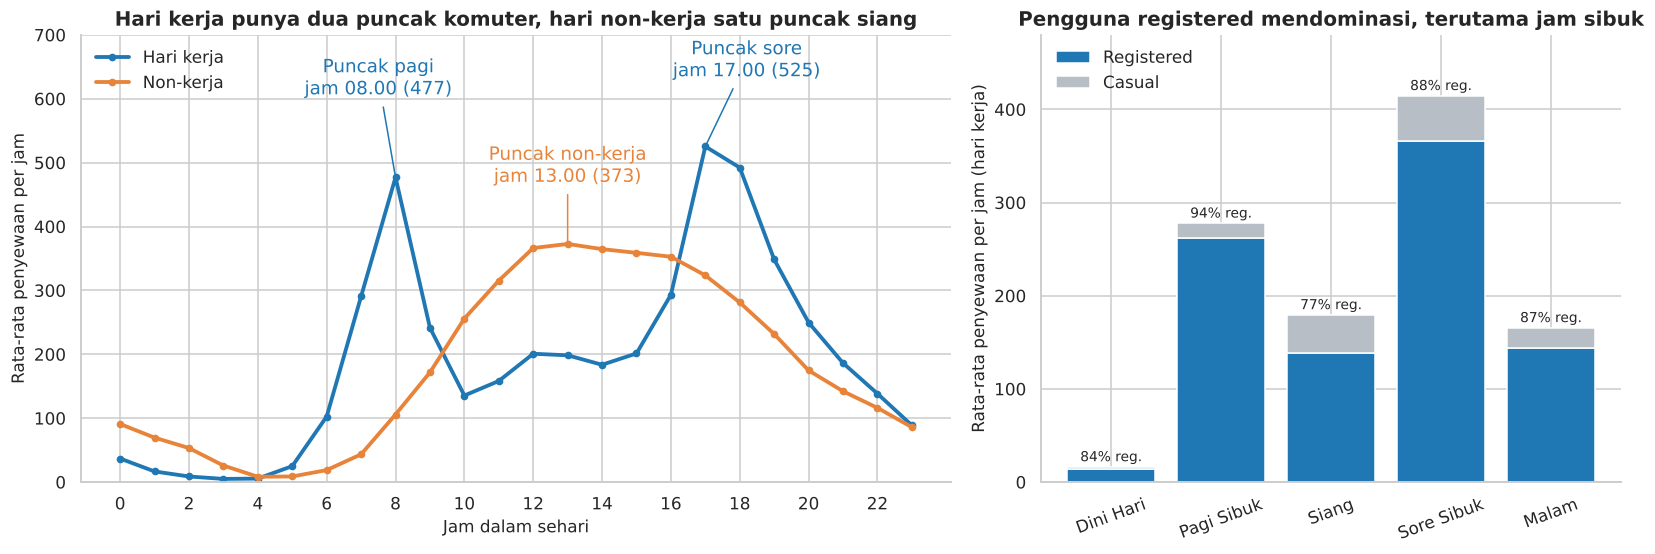

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})

# (a) Pola rata-rata penyewaan per jam
ax = axes[0]
for dtype_label, color in [("Hari kerja", C_WORK), ("Non-kerja", C_OFF)]:
    ax.plot(hourly.index, hourly[dtype_label], color=color, linewidth=2.5, marker="o",
            markersize=4, label=dtype_label)

# Anotasi puncak
wk = hourly["Hari kerja"]
ax.annotate(f"Puncak pagi\njam {morning_peak:02d}.00 ({wk[morning_peak]:.0f})", xy=(morning_peak, wk[morning_peak]),
            xytext=(morning_peak - 0.5, wk[morning_peak] + 130), ha="center", color=C_WORK,
            arrowprops=dict(arrowstyle="-", color=C_WORK))
ax.annotate(f"Puncak sore\njam {evening_peak:02d}.00 ({wk[evening_peak]:.0f})", xy=(evening_peak, wk[evening_peak]),
            xytext=(evening_peak + 1.2, wk[evening_peak] + 110), ha="center", color=C_WORK,
            arrowprops=dict(arrowstyle="-", color=C_WORK))
off = hourly["Non-kerja"]
off_peak = off.idxmax()
ax.annotate(f"Puncak non-kerja\njam {off_peak:02d}.00 ({off[off_peak]:.0f})", xy=(off_peak, off[off_peak]),
            xytext=(13, 470), ha="center", color=C_OFF,
            arrowprops=dict(arrowstyle="-", color=C_OFF))

ax.set_title("Hari kerja punya dua puncak komuter, hari non-kerja satu puncak siang")
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(0, 700)
ax.legend(frameon=False, loc="upper left")

# (b) Komposisi pengguna per segmen waktu, hari kerja
ax = axes[1]
seg = segment_stats.loc["Hari kerja", ["registered", "casual"]]
ax.bar(seg.index.astype(str), seg["registered"], color=C_WORK, label="Registered")
ax.bar(seg.index.astype(str), seg["casual"], bottom=seg["registered"], color=C_MUTED, label="Casual")
for i, (r, c) in enumerate(zip(seg["registered"], seg["casual"])):
    ax.text(i, r + c + 6, f"{r / (r + c) * 100:.0f}% reg.", ha="center", fontsize=9)
ax.set_title("Pengguna registered mendominasi, terutama jam sibuk")
ax.set_ylabel("Rata-rata penyewaan per jam (hari kerja)")
ax.set_ylim(0, 480)
ax.tick_params(axis="x", rotation=20)
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

**Penjelasan:** Garis biru menunjukkan pola hari kerja dengan dua lonjakan yang sejalan dengan jam berangkat dan pulang kerja. Garis oranye (hari non-kerja) meningkat bertahap dan memuncak di sekitar tengah hari. Grafik kanan memperlihatkan bahwa pada segmen Pagi Sibuk dan Sore Sibuk hari kerja, hampir seluruh penyewa adalah pengguna registered.

### Pertanyaan 2: Berapa persen penurunan rata-rata penyewaan harian saat cuaca berawan/berkabut dan hujan/salju ringan dibandingkan cerah, dan musim apa dengan rata-rata tertinggi?

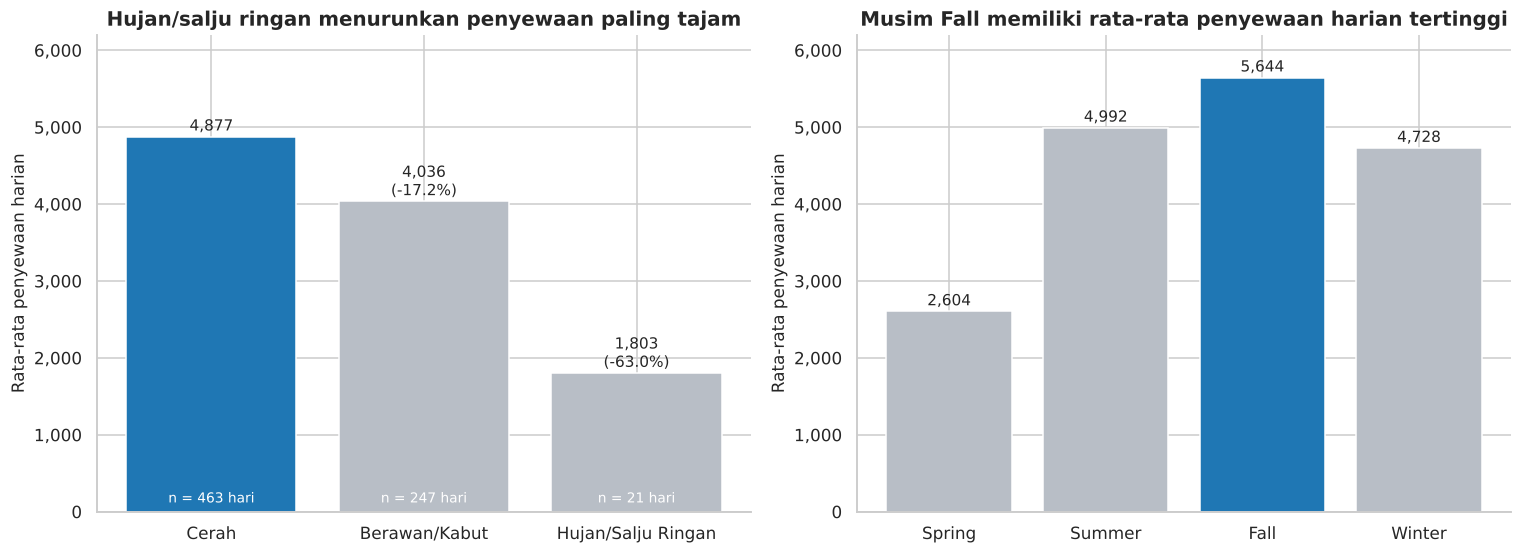

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# (a) Cuaca
ax = axes[0]
w = weather_stats.copy()
colors = [C_HIGHLIGHT, C_MUTED, C_MUTED]
bars = ax.bar(w.index, w["rata2_cnt"], color=colors)
for bar, pct, n in zip(bars, w["selisih_vs_cerah_%"], w["jumlah_hari"]):
    label = f"{bar.get_height():,.0f}" if pct == 0 else f"{bar.get_height():,.0f}\n({pct:+.1f}%)"
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80, label, ha="center", fontsize=10)
    ax.text(bar.get_x() + bar.get_width() / 2, 120, f"n = {n} hari", ha="center", color="white", fontsize=9)
ax.set_title("Hujan/salju ringan menurunkan penyewaan paling tajam")
ax.set_ylabel("Rata-rata penyewaan harian")
ax.set_ylim(0, 6200)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))

# (b) Musim
ax = axes[1]
s = season_stats
top = s["rata2_cnt"].idxmax()
colors = [C_HIGHLIGHT if idx == top else C_MUTED for idx in s.index]
bars = ax.bar(s.index, s["rata2_cnt"], color=colors)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80, f"{bar.get_height():,.0f}",
            ha="center", fontsize=10)
ax.set_title(f"Musim {top} memiliki rata-rata penyewaan harian tertinggi")
ax.set_ylabel("Rata-rata penyewaan harian")
ax.set_ylim(0, 6200)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))

plt.tight_layout()
plt.show()

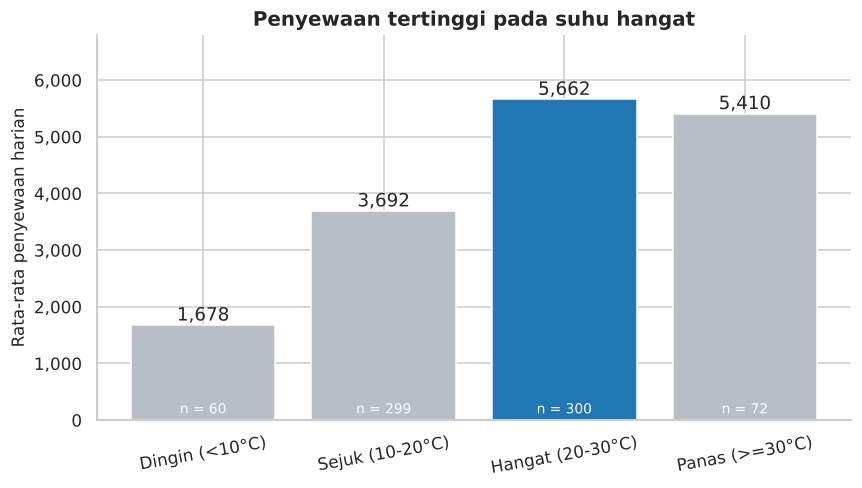

In [32]:
# Pelengkap (hasil binning suhu): penyewaan harian menurut rentang suhu
fig, ax = plt.subplots(figsize=(8, 4.6))
t = temp_stats
top_t = t["rata2_cnt"].idxmax()
colors = [C_HIGHLIGHT if idx == top_t else C_MUTED for idx in t.index]
bars = ax.bar(t.index.astype(str), t["rata2_cnt"], color=colors)
for bar, n in zip(bars, t["jumlah_hari"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80, f"{bar.get_height():,.0f}", ha="center")
    ax.text(bar.get_x() + bar.get_width() / 2, 120, f"n = {n}", ha="center", color="white", fontsize=9)
ax.set_title("Penyewaan tertinggi pada suhu hangat")
ax.set_ylabel("Rata-rata penyewaan harian")
ax.set_ylim(0, 6800)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

**Penjelasan:** Batang biru adalah kategori yang menjadi pembanding/sorotan. Cuaca berawan menurunkan penyewaan secara moderat, sedangkan hujan/salju ringan menurunkannya sangat tajam (perhatikan jumlah hari pada kategori ini jauh lebih sedikit sehingga perlu kehati-hatian dalam generalisasi). Musim Fall unggul, sementara Spring paling rendah. Hasil binning suhu memperkuat pola ini.

### Pertanyaan 3: Berapa persen pertumbuhan rata-rata penyewaan harian 2012 dibanding 2011, dan pada bulan apa pertumbuhan paling tinggi dan paling rendah?

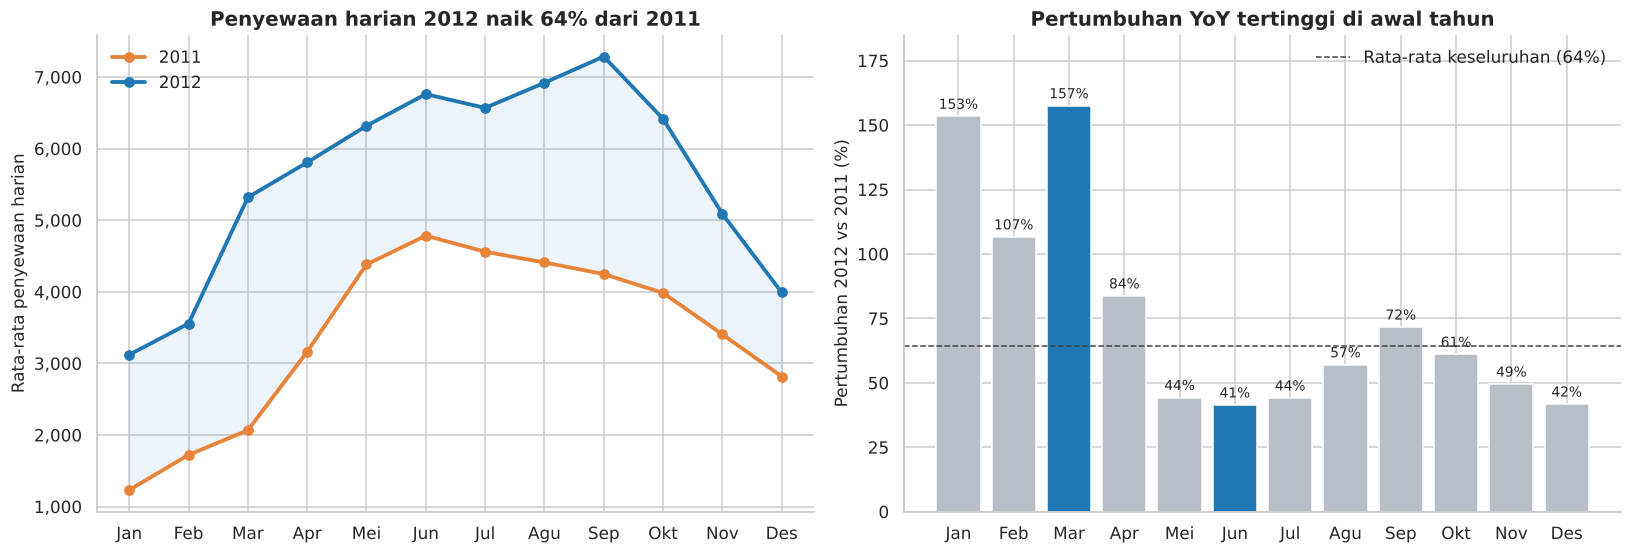

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# (a) Tren bulanan 2011 vs 2012
ax = axes[0]
months = list(monthly.index)
ax.plot(months, monthly[2011], color=C_OFF, linewidth=2.5, marker="o", label="2011")
ax.plot(months, monthly[2012], color=C_WORK, linewidth=2.5, marker="o", label="2012")
ax.fill_between(months, monthly[2011], monthly[2012], color=C_WORK, alpha=0.08)
ax.set_title(f"Penyewaan harian 2012 naik {yoy_overall:.0f}% dari 2011")
ax.set_ylabel("Rata-rata penyewaan harian")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.legend(frameon=False, loc="upper left")

# (b) Pertumbuhan YoY per bulan
ax = axes[1]
g = monthly["pertumbuhan_%"]
colors = [C_HIGHLIGHT if v in (g.max(), g.min()) else C_MUTED for v in g]
bars = ax.bar(months, g, color=colors)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3, f"{bar.get_height():.0f}%",
            ha="center", fontsize=9)
ax.axhline(yoy_overall, color="#444444", linestyle="--", linewidth=1,
           label=f"Rata-rata keseluruhan ({yoy_overall:.0f}%)")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Pertumbuhan YoY tertinggi di awal tahun")
ax.set_ylabel("Pertumbuhan 2012 vs 2011 (%)")
ax.set_ylim(0, 185)

plt.tight_layout()
plt.show()

**Penjelasan:** Garis biru (2012) berada di atas garis oranye (2011) pada seluruh bulan. Batang yang disorot adalah bulan dengan pertumbuhan tertinggi dan terendah. Pertumbuhan persentase di awal tahun tampak besar karena basis 2011 pada bulan-bulan tersebut masih rendah.

## Conclusion

**Kesimpulan Pertanyaan 1 (Pola jam):**
- Pada **hari kerja** terdapat dua puncak: pagi sekitar **jam 08.00** (rata-rata sekitar 477 penyewaan per jam) dan sore sekitar **jam 17.00** (sekitar 525 penyewaan per jam). Puncak sore adalah yang tertinggi.
- Pada **hari non-kerja** hanya ada satu puncak di sekitar **jam 13.00** (sekitar 373 penyewaan per jam), dengan pola yang landai sepanjang siang.
- Pada jam puncak hari kerja, sekitar **95% (pagi)** dan **89% (sore)** penyewa adalah pengguna **registered**, yang menandakan penggunaan sebagai sarana komuter.

**Kesimpulan Pertanyaan 2 (Cuaca dan musim):**
- Dibanding cuaca cerah (sekitar 4.877 penyewaan per hari), rata-rata penyewaan harian turun sekitar **17%** saat berawan/berkabut dan sekitar **63%** saat hujan/salju ringan.
- Musim **Fall** memiliki rata-rata harian tertinggi (sekitar 5.644), sedangkan **Spring** terendah (sekitar 2.604). Penyewaan juga tertinggi pada rentang suhu hangat (20-30°C).
- Catatan: kategori hujan/salju ringan hanya memiliki 21 hari, sehingga angkanya perlu dibaca hati-hati.

**Kesimpulan Pertanyaan 3 (Pertumbuhan):**
- Rata-rata penyewaan harian 2012 (sekitar 5.600) naik sekitar **64%** dibanding 2011 (sekitar 3.406), dan 2012 lebih tinggi di semua bulan.
- Pertumbuhan YoY tertinggi terjadi pada **Maret (sekitar 157%)** dan **Januari (sekitar 153%)**, terendah pada **Juni (sekitar 41%)** dan **Desember (sekitar 42%)**. Angka awal tahun besar sebagian karena basis 2011 yang rendah.

## Rekomendasi (Action Items)
1. **Redistribusi sepeda terjadwal pada hari kerja:** pastikan stasiun area permukiman terisi penuh sebelum jam 07.00 dan stasiun area perkantoran siap menampung/menyediakan sepeda sebelum jam 16.00. Alokasikan petugas rebalancing sekitar jam 06.00 dan 15.00. Untuk akhir pekan, fokuskan ketersediaan sepeda pada jam 11.00-15.00.
2. **Strategi promosi berbasis cuaca dan musim:** jalankan promosi pada musim Spring atau saat cuaca berawan (misalnya diskon atau paket langganan), dan jadwalkan perawatan armada pada periode permintaan rendah seperti saat hujan. Siapkan kapasitas penuh pada musim Fall.
3. **Rencana kapasitas armada:** karena pertumbuhan 2012 sangat kuat, tambahkan armada sebelum musim ramai (menjelang Mei-Oktober) dan pantau apakah pertumbuhan masih berlanjut pada tahun-tahun berikutnya.
4. **Peluang pengguna casual:** pengguna casual relatif lebih banyak pada hari non-kerja siang hari, sehingga paket harian atau akhir pekan dapat menjadi target konversi menjadi anggota.

*Catatan keterbatasan:* analisis ini bersifat deskriptif (korelasi, bukan sebab-akibat), data hanya mencakup dua tahun, dan sekitar 165 jam tidak tercatat pada data per jam.